# Filtros de suavizado: respuesta al tipo de ruido

**Trabajo Práctico N°3 – Filtros** · Fundamentos del Procesamiento Digital de Imágenes · Grupo N°4
Actividad 1 desarrollada por Brian Aranda.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/tp3/code/ejercicio_1/filtros_suavizado.ipynb)

**Consigna.** Se contamina una imagen limpia con ruido gaussiano (σ = 15, 25 y 40) y con ruido sal y pimienta (5, 10 y 20 %). Cada versión se filtra con media y mediana de 3×3, 5×5 y 7×7, y con un filtro gaussiano de σ = 1, 2 y 3. Los resultados se comparan a la vista y con PSNR y SSIM.

## 1. Configuración

### Ejecución en Google Colab

En Colab la celda siguiente clona el repositorio y se ubica en `code/ejercicio_1/`. En una ejecución local no hace nada.

In [1]:
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    RAMA = "tp3"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_1")
    print("Trabajando en", os.getcwd())

### Librerías y carpetas

In [2]:
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox
from skimage.metrics import structural_similarity

DIR_FIG = Path("../../img/ejercicio_1")   # figuras del informe
DIR_FIG.mkdir(parents=True, exist_ok=True)

# Exportar las figuras del informe. Queda apagado para no modificar los PDFs al ejecutar
EXPORTAR_FIGURAS = False
FORMATO_FIGURAS = "pdf"   # "png" para revisar tamaños

# Solo se exportan estas figuras
FIGURAS_INFORME = {"referencia", "ruidosas", "filtros_gaussiano", "filtros_sal_pimienta", "metricas",
                   "tamano_kernel", "metricas_percepcion", "perfil_borde", "media_gaussiano"}

SEMILLA = 527   # el ruido sale igual en cada ejecución

### Figuras con la tipografía del informe

In [3]:
# Las figuras del notebook se guardan en JPEG para que pese menos.
# Las del informe se exportan aparte en PDF con guardar()
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

# Ancho de texto del informe en la rama tp3: \the\linewidth = 469.47049 pt (1 in = 72.27 pt)
ANCHO = 469.47049 / 72.27   # ≈ 6.50 in


def ancho(fraccion=1.0):
    # Ancho de una figura que ocupa `fraccion` del \linewidth. En LaTeX se inserta sin escalar
    return fraccion * ANCHO


plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "grid.alpha": 0.4,

    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,

    "figure.figsize": (ANCHO, 4),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.format": "pdf",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,

    "figure.constrained_layout.use": True,
    "figure.constrained_layout.w_pad": 0.04,   # margen lateral para que no se corten bordes ni números
    "figure.constrained_layout.h_pad": 0.02,
    "figure.constrained_layout.wspace": 0.02,
    "figure.constrained_layout.hspace": 0.02,
})


def guardar(fig, nombre, margen=0.06):
    # Exporta a img/ejercicio_1/<nombre>.pdf sin títulos (el título va en el caption de LaTeX).
    # El ancho queda exacto y solo se recorta el blanco de arriba y de abajo
    if not EXPORTAR_FIGURAS or nombre not in FIGURAS_INFORME:
        return
    titulos = [ax.get_title() for ax in fig.axes]
    titulo_general = fig.get_suptitle()
    for ax in fig.axes:
        ax.set_title("")
    fig.suptitle("")
    fig.canvas.draw()
    contenido = fig.get_tightbbox(fig.canvas.get_renderer())   # en pulgadas
    caja = Bbox.from_extents(0, contenido.y0 - margen, fig.get_figwidth(), contenido.y1 + margen)
    # Sin fecha de creación: si la figura no cambió, el PDF es idéntico y git no lo marca
    fig.savefig(DIR_FIG / f"{nombre}.{FORMATO_FIGURAS}", bbox_inches=caja,
                metadata={"CreationDate": None} if FORMATO_FIGURAS == "pdf" else None)
    for ax, titulo in zip(fig.axes, titulos):
        ax.set_title(titulo)
    fig.suptitle(titulo_general)


def mostrar_img(ax, img, texto="", letra="", **kwargs):
    # Imagen en grises sin ejes, con el rótulo "(a) texto" debajo.
    # Sin interpolar, para que el ruido se vea tal cual
    opciones = {"cmap": "gray", "vmin": 0, "vmax": 255, "interpolation": "nearest"}
    ax.imshow(img, **{**opciones, **kwargs})
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"({letra}) {texto}" if letra else texto)


def etiquetar(ax, letra, texto="", derecha=False):
    # Rótulo "(a) texto" en una esquina de arriba, dentro de un gráfico con ejes
    rotulo = f"({letra}) {texto}" if texto else f"({letra})"
    ax.text(0.97 if derecha else 0.03, 0.95, rotulo, transform=ax.transAxes, va="top",
            ha="right" if derecha else "left",
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))


LETRAS = "abcdefghijklmnopqrstuvwxyz"

# Un color por familia de filtro y una rampa de azules para los niveles de ruido
COLOR = {"Media": "#2a78d6", "Mediana": "#eb6834", "Gaussiano": "#1baf7a"}
GRIS = "#52514e"
NIVELES = ["#86b6ef", "#2a78d6", "#104281"]   # de menos a más ruido
AZULES = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## 2. Imagen de referencia

### Preparación

La foto es de una disquería de Oberá. Se tomó con un Samsung A04 a ISO 500, con poca luz, y se guardó en JPEG de 6120×6120 píxeles. Se pasa a escala de grises y se reduce a 1020×1020 con `INTER_AREA`, que promedia bloques de 6×6 píxeles.

In [4]:
# imread no abre rutas con tildes en Windows: se leen los bytes y se decodifican
foto = cv2.imdecode(np.fromfile("disqueria.jpeg", np.uint8), cv2.IMREAD_COLOR)
gris = cv2.cvtColor(foto, cv2.COLOR_BGR2GRAY)
ref = cv2.resize(gris, (1020, 1020), interpolation=cv2.INTER_AREA)
print(f"Foto {gris.shape[1]}×{gris.shape[0]} → referencia {ref.shape[1]}×{ref.shape[0]}")

# A resolución completa el detalle ocupa varios píxeles y un kernel de 3×3 casi no lo toca
for nombre, img in (("completa", gris), ("reducida", ref)):
    print(f"Resolución {nombre}: PSNR contra su media 3×3 = {cv2.PSNR(img, cv2.blur(img, (3, 3))):.1f} dB")

oscuros = (ref < 40).mean()
print(f"Píxeles por debajo de 40: {100 * oscuros:.0f} %")

Foto 6120×6120 → referencia 1020×1020
Resolución completa: PSNR contra su media 3×3 = 46.7 dB
Resolución reducida: PSNR contra su media 3×3 = 30.1 dB
Píxeles por debajo de 40: 41 %


Las figuras usan cuatro zonas de la imagen. La zona 1 tiene la pared lisa, los bordes de las guitarras y las cuerdas, que miden un píxel de ancho. Las otras se usan en el análisis.

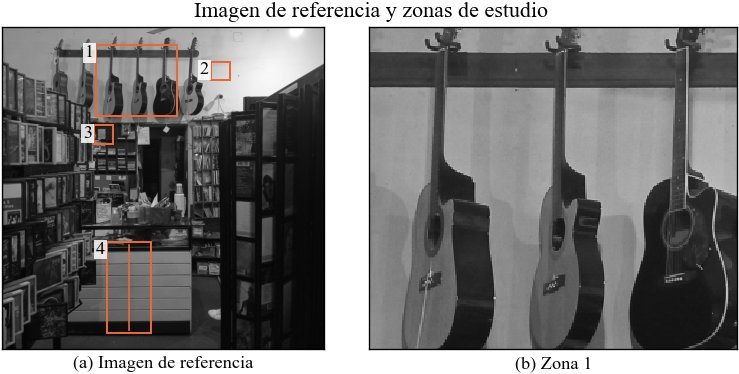

In [5]:
ZONAS = {
    1: np.s_[57:281, 296:552],    # guitarras: recorte de las grillas
    2: np.s_[110:170, 660:720],   # pared lisa
    3: np.s_[312:372, 290:350],   # pila de casetes
    4: np.s_[680:970, 330:470],   # mostrador: el perfil va por la columna 400
}
RECORTE = ZONAS[1]
COL_PERFIL, FILAS_PERFIL = 400, slice(690, 960)


def dibujar_zona(ax, zona, etiqueta, color="#eb6834"):
    y, x = zona
    ax.add_patch(Rectangle((x.start - 0.5, y.start - 0.5), x.stop - x.start, y.stop - y.start,
                           fill=False, ec=color, lw=1.2))
    ax.text(x.start - 6, y.start, etiqueta, color="black", va="top", ha="right",
            bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))


alto_rec, ancho_rec = ref[RECORTE].shape
fig, axs = plt.subplots(1, 2, figsize=(ancho(1.0), 3.12), width_ratios=[1, ancho_rec / alto_rec])
mostrar_img(axs[0], ref, "Imagen de referencia", "a", interpolation="antialiased")
for n, zona in ZONAS.items():
    dibujar_zona(axs[0], zona, str(n))
axs[0].plot([COL_PERFIL] * 2, [FILAS_PERFIL.start, FILAS_PERFIL.stop], color="#eb6834", lw=1)
mostrar_img(axs[1], ref[RECORTE], "Zona 1", "b")
fig.suptitle("Imagen de referencia y zonas de estudio")
guardar(fig, "referencia")
plt.show()

### Ruido propio de la foto

Para usarla como referencia, el ruido propio de la foto tiene que ser chico frente a σ = 15. Se mide el desvío en tres zonas lisas de la pared. Antes se les resta un suavizado, que quita la variación lenta de la iluminación.

In [6]:
ZONAS_LISAS = [np.s_[150:200, 640:720], np.s_[40:80, 820:900], np.s_[100:140, 690:770]]
for z in ZONAS_LISAS:
    reducida = ref[z].astype(float)
    y, x = z
    completa = gris[6 * y.start:6 * y.stop, 6 * x.start:6 * x.stop].astype(float)
    d_red = (reducida - cv2.GaussianBlur(reducida, (0, 0), 3)).std()
    d_comp = (completa - cv2.GaussianBlur(completa, (0, 0), 18)).std()
    print(f"Nivel medio {reducida.mean():.0f}: desvío {d_red:.2f} en la reducida y {d_comp:.2f} en la completa")

Nivel medio 210: desvío 1.06 en la reducida y 1.79 en la completa
Nivel medio 226: desvío 0.94 en la reducida y 1.64 en la completa
Nivel medio 215: desvío 1.39 en la reducida y 2.14 en la completa


El desvío queda cerca de 1 nivel de gris. Frente al ruido más chico (σ = 15) aporta menos del 1 % de la varianza, así que la imagen reducida se toma como limpia.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Imagen | Foto propia de una disquería de Oberá | Tiene zonas lisas (pared), bordes netos (guitarras, mostrador) y detalle fino (cuerdas, casetes, texto) | — | — | Visual |
| Color | Escala de grises | El ruido, los filtros y las métricas se calculan sobre un solo canal | Filtrar los tres canales | La mediana por canal puede inventar colores, y PSNR y SSIM habría que combinarlos | — |
| Resolución | 1020×1020, con promedio de bloques de 6×6 (`INTER_AREA`) | El detalle queda a la escala de los kernels de la consigna, y baja el ruido propio | Resolución completa (6120×6120) | Una media de 3×3 casi no cambia la imagen (PSNR de 46,7 dB contra 30,1 dB en la reducida). Además son 37 millones de píxeles por imagen | Métrica (PSNR) |
| Referencia limpia | Se acepta la imagen reducida | Su ruido propio es de 1 nivel de gris en la pared, contra unos 2 en la completa | — | — | Métrica (desvío en zonas lisas) |
| Zona de las grillas | Guitarras (zona 1, 256×224 píxeles) | Junta pared lisa, bordes netos y líneas de un píxel (cuerdas) | Mostrador con carteles | Mucho detalle mezclado, cuesta ver el ruido | Visual |

## 3. Imágenes con ruido

### Funciones de ruido

El ruido gaussiano se suma en niveles de gris y después se recorta a [0, 255]. El sal y pimienta cambia una fracción de píxeles elegidos al azar, la mitad a 0 y la otra mitad a 255. Las dos funciones usan la misma semilla en todos los niveles. Así el ruido de σ = 40 es el mismo patrón que el de σ = 15, pero más fuerte, y los píxeles del 5 % también están en el 10 % y en el 20 %.

In [7]:
def ruido_gaussiano(img, sigma, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    ruidosa = img + rng.normal(0, sigma, img.shape)
    return np.clip(ruidosa, 0, 255).round().astype(np.uint8)


def ruido_sal_pimienta(img, densidad, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    elegidos = rng.random(img.shape) < densidad
    sal = rng.random(img.shape) < 0.5
    ruidosa = img.copy()
    ruidosa[elegidos & ~sal] = 0
    ruidosa[elegidos & sal] = 255
    return ruidosa


def nombre_ruido(tipo, nivel):
    return f"Gaussiano σ = {nivel}" if tipo == "Gaussiano" else f"Sal y pimienta {nivel}%"


def metricas(img):
    return cv2.PSNR(ref, img), structural_similarity(ref, img, data_range=255)

### Las seis versiones

In [8]:
RUIDOS = {}
for sigma in (15, 25, 40):
    RUIDOS[("Gaussiano", sigma)] = ruido_gaussiano(ref, sigma)
for densidad in (5, 10, 20):
    RUIDOS[("Sal y pimienta", densidad)] = ruido_sal_pimienta(ref, densidad / 100)

filas = []
for (tipo, nivel), img in RUIDOS.items():
    dif = img.astype(float) - ref
    psnr, ssim = metricas(img)
    filas.append({"Ruido": nombre_ruido(tipo, nivel), "PSNR (dB)": psnr, "SSIM": ssim,
                  "Cambiados (%)": 100 * (img != ref).mean(),
                  "En 0 (%)": 100 * (img == 0).mean(), "En 255 (%)": 100 * (img == 255).mean(),
                  "Desvío real": dif.std() if tipo == "Gaussiano" else np.nan,
                  "Diferencia media": dif.mean() if tipo == "Gaussiano" else np.nan})
pd.DataFrame(filas).set_index("Ruido").round(2)

,PSNR (dB),SSIM,Cambiados (%),En 0 (%),En 255 (%),Desvío real,Diferencia media
Ruido,,,,,,,
Gaussiano σ = 15,25.00,0.46,97.32,5.79,0.48,14.34,0.44
Gaussiano σ = 25,20.87,0.30,98.39,10.27,0.97,23.02,1.39
Gaussiano σ = 40,17.17,0.19,98.98,15.24,1.72,35.16,3.46
Sal y pimienta 5%,17.48,0.36,5.02,2.51,2.55,NaN,NaN
Sal y pimienta 10%,14.48,0.19,10.02,5.01,5.05,NaN,NaN
Sal y pimienta 20%,11.50,0.09,19.96,9.99,10.00,NaN,NaN


Con σ = 40 queda en 0 el 15 % de los píxeles. La foto es oscura, así que el recorte a [0, 255] corta mucho ruido negativo. Por eso el desvío real es menor que el pedido y la imagen ruidosa queda, en promedio, un poco más clara.

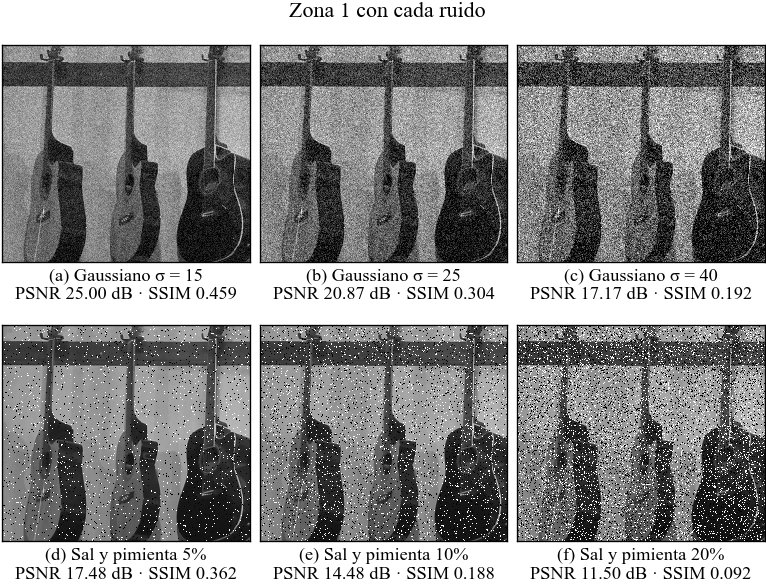

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(ancho(1.0), 4.86))
fig.get_layout_engine().set(rect=(0, 0, 0.99, 1))   # más margen a la derecha
for i, (ax, ((tipo, nivel), img)) in enumerate(zip(axs.flat, RUIDOS.items())):
    psnr, ssim = metricas(img)
    mostrar_img(ax, img[RECORTE], f"{nombre_ruido(tipo, nivel)}\nPSNR {psnr:.2f} dB · SSIM {ssim:.3f}", LETRAS[i])
fig.suptitle("Zona 1 con cada ruido")
guardar(fig, "ruidosas")
plt.show()

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Ruido gaussiano | Función propia, en niveles de gris, con recorte a [0, 255] y redondeo | σ queda en las mismas unidades que la consigna | `random_noise` de scikit-image | Trabaja en [0, 1] y al pasar a uint8 hay que cuidar el redondeo | — |
| Ruido sal y pimienta | Función propia, mitad 0 y mitad 255 | Es lo que pide la consigna | — | — | — |
| Semilla | La misma (527) en todos los niveles | Los resultados se repiten y los niveles se comparan con el mismo patrón | Una semilla distinta por nivel | Cada nivel tendría un patrón distinto | — |
| Recorte a [0, 255] | Se mantiene | Una imagen de 8 bits no puede tener valores fuera del rango, y la mediana de 7×7 de OpenCV solo acepta uint8 | Trabajar en punto flotante sin recortar | La imagen ruidosa no se podría guardar ni mostrar tal cual | — |

## 4. Filtros y métricas

### Filtros

La media usa `cv2.blur`, la mediana `cv2.medianBlur` y el gaussiano `cv2.GaussianBlur`. El tamaño del kernel gaussiano es el impar que cubre ±3σ, o sea 6σ + 1.

In [10]:
def tam_gaussiano(sigma):
    return 2 * int(np.ceil(3 * sigma)) + 1


def gaussiano(img, sigma):
    return cv2.GaussianBlur(img, (tam_gaussiano(sigma),) * 2, sigma)


FILTROS = {}
for k in (3, 5, 7):
    FILTROS[("Media", k)] = lambda img, k=k: cv2.blur(img, (k, k))
for k in (3, 5, 7):
    FILTROS[("Mediana", k)] = lambda img, k=k: cv2.medianBlur(img, k)
for sigma in (1, 2, 3):
    FILTROS[("Gaussiano", sigma)] = lambda img, sigma=sigma: gaussiano(img, sigma)


def nombre_filtro(familia, p):
    if familia == "Gaussiano":
        return f"Gaussiano σ = {p}"
    return f"{familia} {p}×{p}" if p else familia


print("Tamaño del kernel gaussiano:", {s: tam_gaussiano(s) for s in (1, 2, 3)})

Tamaño del kernel gaussiano: {1: 7, 2: 13, 3: 19}


### Barrido

In [11]:
filtradas = {}
filas = []
for (tipo, nivel), ruidosa in RUIDOS.items():
    psnr, ssim = metricas(ruidosa)
    filas.append({"tipo": tipo, "nivel": nivel, "familia": "Sin filtrar", "param": 0,
                  "filtro": "Sin filtrar", "PSNR": psnr, "SSIM": ssim})
    for (familia, p), filtro in FILTROS.items():
        img = filtro(ruidosa)
        filtradas[(tipo, nivel, familia, p)] = img
        psnr, ssim = metricas(img)
        filas.append({"tipo": tipo, "nivel": nivel, "familia": familia, "param": p,
                      "filtro": nombre_filtro(familia, p), "PSNR": psnr, "SSIM": ssim})
res = pd.DataFrame(filas)

tabla_psnr = res.pivot_table(index="filtro", columns=["tipo", "nivel"], values="PSNR", sort=False)
tabla_ssim = res.pivot_table(index="filtro", columns=["tipo", "nivel"], values="SSIM", sort=False)
display(tabla_psnr.round(2))
display(tabla_ssim.round(3))

tipo            Gaussiano               Sal y pimienta              
nivel                  15     25     40             5      10     20
filtro                                                              
Sin filtrar         25.00  20.87  17.17          17.48  14.48  11.50
Media 3×3           28.66  26.94  24.35          24.86  22.23  18.97
Media 5×5           26.77  26.16  24.78          25.26  23.46  20.50
Media 7×7           25.65  25.30  24.37          24.78  23.44  20.81
Mediana 3×3         28.74  26.22  23.29          31.36  30.58  27.48
Mediana 5×5         27.45  26.41  24.82          28.16  27.98  27.50
Mediana 7×7         26.38  25.81  24.90          26.73  26.63  26.39
Gaussiano σ = 1     29.25  27.70  25.19          25.77  23.13  19.76
Gaussiano σ = 2     26.63  26.19  25.05          25.54  23.97  21.06
Gaussiano σ = 3     25.12  24.87  24.12          24.50  23.39  20.94

tipo            Gaussiano               Sal y pimienta              
nivel                  15     25     40             5      10     20
filtro                                                              
Sin filtrar         0.459  0.304  0.192          0.362  0.188  0.092
Media 3×3           0.779  0.642  0.482          0.545  0.394  0.262
Media 5×5           0.794  0.723  0.611          0.638  0.517  0.380
Media 7×7           0.764  0.724  0.650          0.672  0.584  0.464
Mediana 3×3         0.723  0.555  0.395          0.945  0.938  0.893
Mediana 5×5         0.785  0.674  0.530          0.888  0.885  0.875
Mediana 7×7         0.782  0.712  0.607          0.846  0.843  0.837
Gaussiano σ = 1     0.820  0.703  0.551          0.606  0.456  0.314
Gaussiano σ = 2     0.808  0.768  0.694          0.718  0.630  0.508
Gaussiano σ = 3     0.752  0.731  0.689          0.711  0.659  0.575

### Resultados a la vista

Una grilla por cada imagen ruidosa. El informe usa las de σ = 25 y sal y pimienta 10 %.

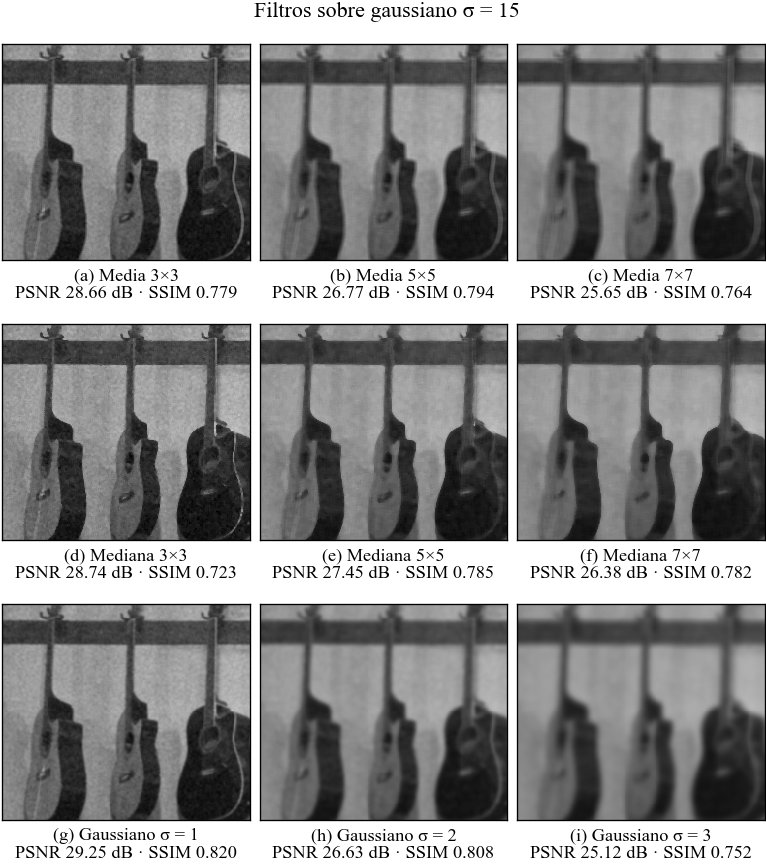

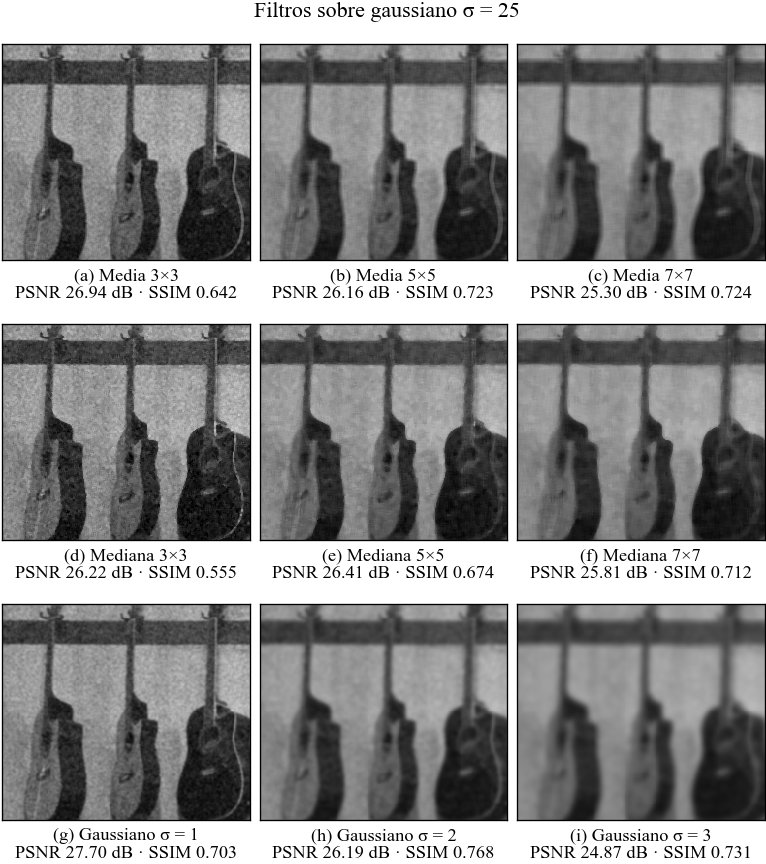

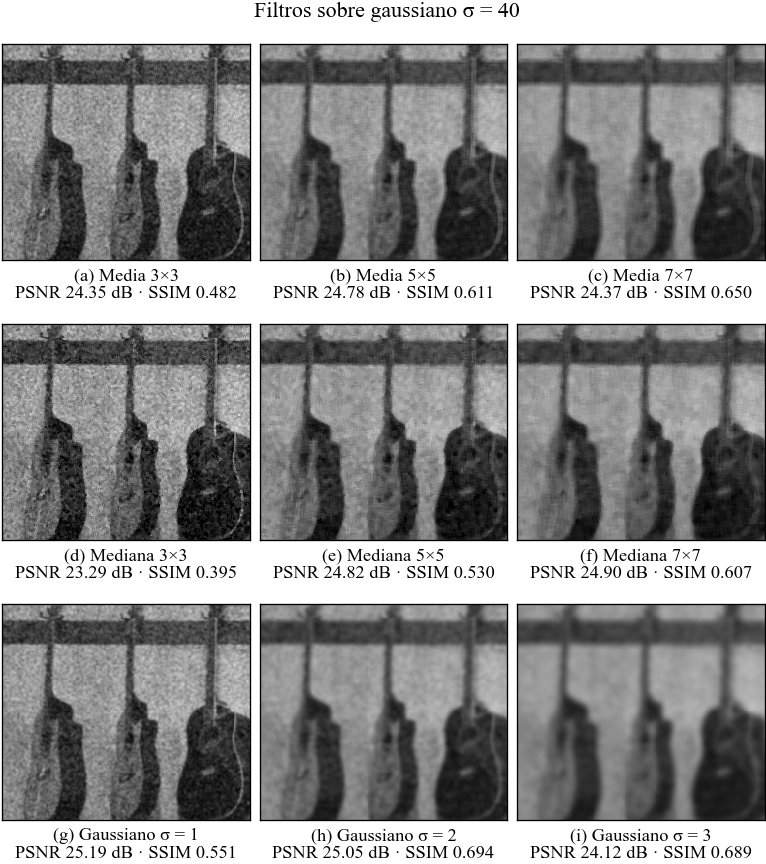

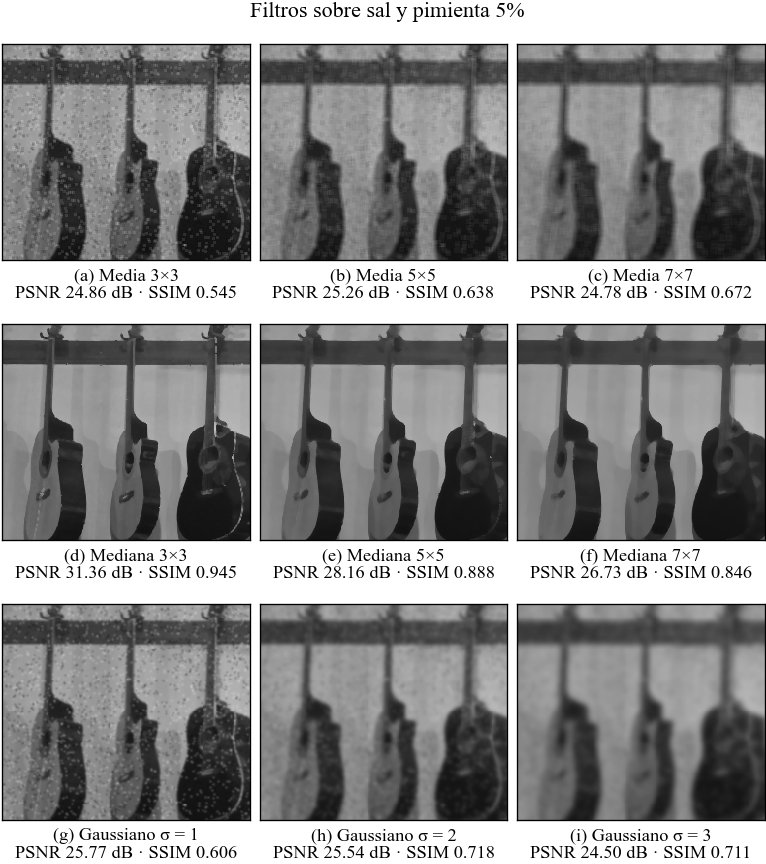

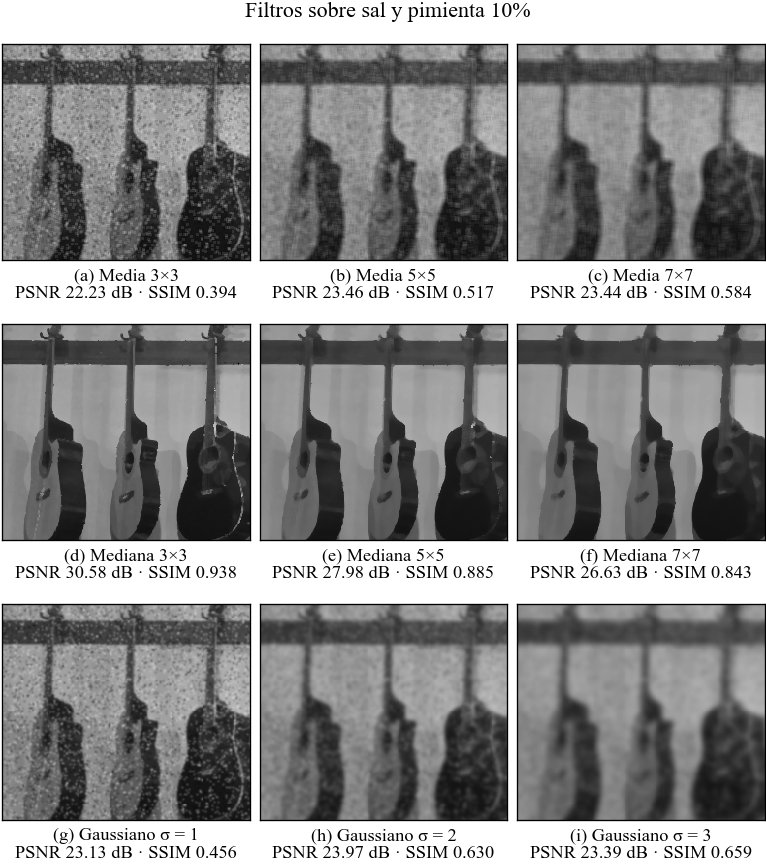

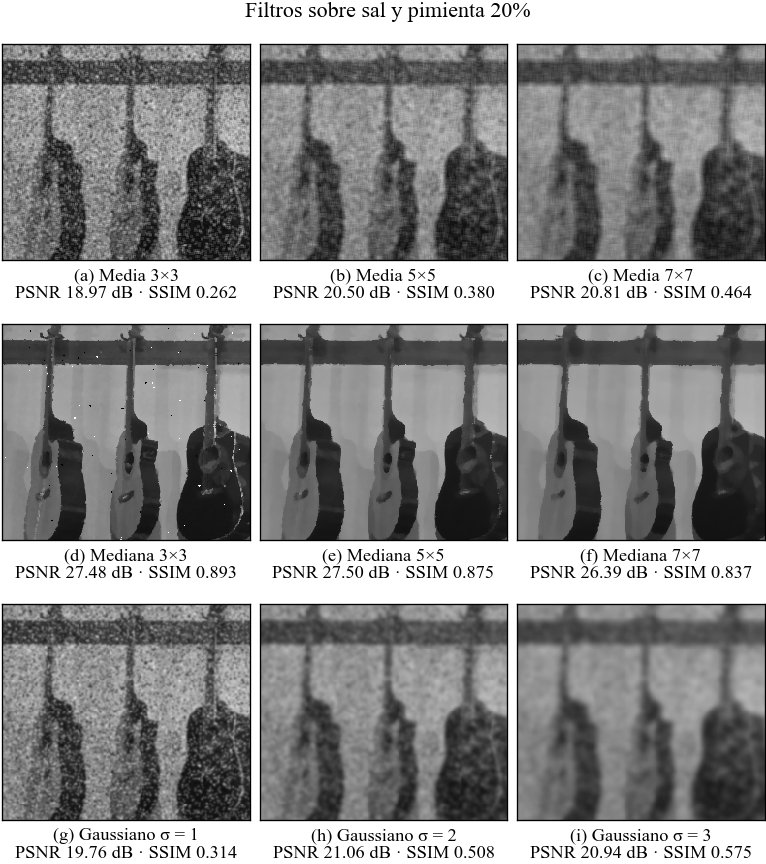

In [12]:
def grilla_filtros(tipo, nivel, nombre=None):
    fig, axs = plt.subplots(3, 3, figsize=(ancho(1.0), 7.2))
    fig.get_layout_engine().set(rect=(0, 0, 0.99, 1))   # más margen a la derecha
    for i, (ax, (familia, p)) in enumerate(zip(axs.flat, FILTROS)):
        img = filtradas[(tipo, nivel, familia, p)]
        psnr, ssim = metricas(img)
        mostrar_img(ax, img[RECORTE], f"{nombre_filtro(familia, p)}\nPSNR {psnr:.2f} dB · SSIM {ssim:.3f}", LETRAS[i])
    fig.suptitle(f"Filtros sobre {nombre_ruido(tipo, nivel).lower()}")
    if nombre:
        guardar(fig, nombre)
    plt.show()


EXPORTADAS = {("Gaussiano", 25): "filtros_gaussiano", ("Sal y pimienta", 10): "filtros_sal_pimienta"}
for tipo, nivel in RUIDOS:
    grilla_filtros(tipo, nivel, EXPORTADAS.get((tipo, nivel)))

### Tabla de métricas

El color de cada celda va del peor al mejor filtro de su columna, así que la celda más oscura es el mejor filtro para ese ruido. El mejor valor de cada columna va en negrita. La fila sin filtrar queda en gris, como referencia.

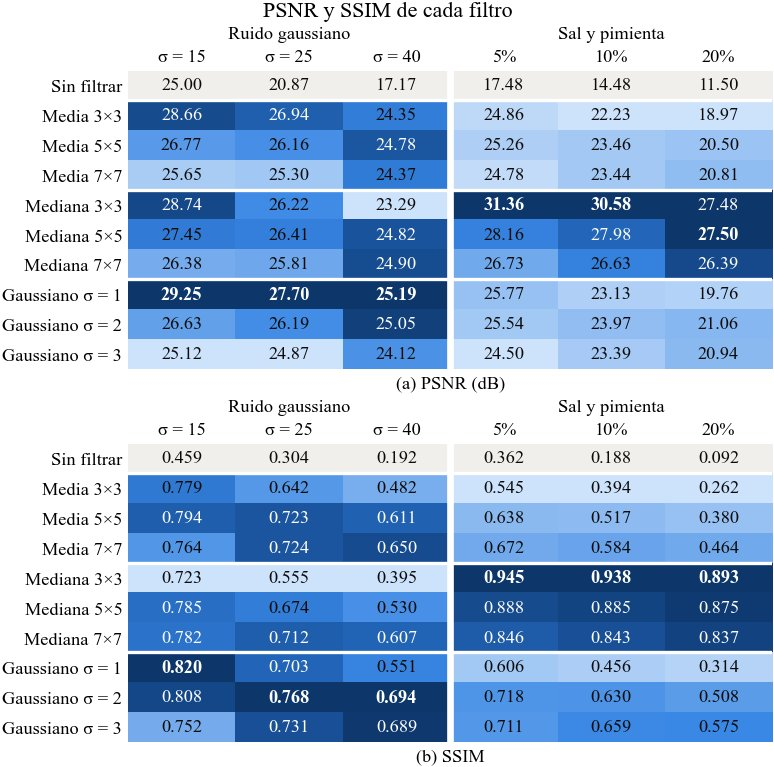

Mejor filtro según cada métrica:


PSNR             SSIM
tipo           nivel                                  
Gaussiano      15     Gaussiano σ = 1  Gaussiano σ = 1
               25     Gaussiano σ = 1  Gaussiano σ = 2
               40     Gaussiano σ = 1  Gaussiano σ = 2
Sal y pimienta 5          Mediana 3×3      Mediana 3×3
               10         Mediana 3×3      Mediana 3×3
               20         Mediana 5×5      Mediana 3×3

In [13]:
COLUMNAS = [f"σ = {n}" if t == "Gaussiano" else f"{n}%" for t, n in tabla_psnr.columns]


def mapa_metrica(ax, tabla, formato, letra, texto):
    v = tabla.to_numpy()
    vf = v[1:]   # filas de los filtros, sin la imagen sin filtrar
    rel = np.vstack([np.full(v.shape[1], np.nan), (vf - vf.min(axis=0)) / (vf.max(axis=0) - vf.min(axis=0))])
    colores = AZULES(np.nan_to_num(rel))
    colores[0] = plt.matplotlib.colors.to_rgba("#f0efec")
    ax.imshow(colores, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, format(v[i, j], formato), ha="center", va="center",
                    color="white" if rel[i, j] > 0.6 else "#0b0b0b",
                    fontweight="bold" if rel[i, j] == 1 else "normal")
    # Separadores entre familias de filtros y entre tipos de ruido
    for y in (0.5, 3.5, 6.5):
        ax.axhline(y, color="white", lw=2)
    ax.axvline(2.5, color="white", lw=4)
    ax.set_yticks(range(len(tabla)), tabla.index)
    ax.set_xticks(range(len(COLUMNAS)), COLUMNAS)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_xlabel(f"({letra}) {texto}")
    # Tipo de ruido sobre las columnas
    for x, rotulo in ((1, "Ruido gaussiano"), (4, "Sal y pimienta")):
        ax.annotate(rotulo, xy=(x, 1), xycoords=("data", "axes fraction"), xytext=(0, 17),
                    textcoords="offset points", ha="center", va="bottom", annotation_clip=False)


fig, axs = plt.subplots(2, 1, figsize=(ancho(1.0), 6.4))
mapa_metrica(axs[0], tabla_psnr, ".2f", "a", "PSNR (dB)")
mapa_metrica(axs[1], tabla_ssim, ".3f", "b", "SSIM")
fig.suptitle("PSNR y SSIM de cada filtro")
guardar(fig, "metricas")
plt.show()

print("Mejor filtro según cada métrica:")
pd.DataFrame({"PSNR": tabla_psnr.drop("Sin filtrar").idxmax(), "SSIM": tabla_ssim.drop("Sin filtrar").idxmax()})

Con ruido gaussiano el mejor PSNR es siempre el del gaussiano de σ = 1. El SSIM elige σ = 1 con el ruido más bajo y σ = 2 con los otros dos. Con sal y pimienta gana la mediana de 3×3, salvo en el PSNR del 20 %, donde la de 5×5 la supera por 0,02 dB. La media y el gaussiano casi no mejoran el sal y pimienta, porque reparten cada impulso entre sus vecinos.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Media | `cv2.blur` | Es el filtro de caja normalizado | `cv2.boxFilter` sin normalizar | Cambia el brillo de la imagen | — |
| Tamaño del gaussiano | 6σ + 1 (7, 13 y 19) | Es la regla de la consigna llevada al impar más cercano, cubre ±3σ | Kernel de 5×5 para todos los σ | Con σ = 3 corta la campana y el filtro deja de ser gaussiano | — |
| Bordes de la imagen | Los de OpenCV por defecto | Afectan solo unos pocos píxeles del contorno | — | — | — |
| PSNR | `cv2.PSNR` sobre toda la imagen | Mide el error cuadrático medio contra la referencia | — | — | — |
| SSIM | `structural_similarity` con `data_range=255` y ventana de 7×7 | Mide la similitud de estructura en ventanas locales | — | — | — |
| Tabla de métricas | Color relativo entre los nueve filtros de cada columna | Los valores de cada ruido son muy distintos, con una escala común no se vería el mejor filtro de cada columna | Incluir la imagen sin filtrar en la escala de cada columna | Casi todos los filtros quedaban oscuros y no se distinguía el mejor | Visual |

## 5. Análisis

### Tamaño del kernel

Se repite el barrido con más tamaños para tres casos, la media y el gaussiano con ruido gaussiano y la mediana con sal y pimienta.

In [14]:
BARRIDO = {
    "Media": ("Gaussiano", [3, 5, 7, 9, 11, 13, 15], lambda img, k: cv2.blur(img, (k, k))),
    "Gaussiano": ("Gaussiano", [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5], gaussiano),
    "Mediana": ("Sal y pimienta", [3, 5, 7, 9, 11, 13, 15], cv2.medianBlur),
}
filas = []
for familia, (tipo, valores, filtro) in BARRIDO.items():
    for nivel in [n for t, n in RUIDOS if t == tipo]:
        for v in valores:
            psnr, ssim = metricas(filtro(RUIDOS[(tipo, nivel)], v))
            filas.append({"familia": familia, "tipo": tipo, "nivel": nivel, "param": v, "PSNR": psnr, "SSIM": ssim})
barrido = pd.DataFrame(filas)

optimos = barrido.loc[barrido.groupby(["familia", "nivel"], sort=False).PSNR.idxmax(), ["familia", "nivel", "param", "PSNR"]]
optimos["param SSIM"] = barrido.loc[barrido.groupby(["familia", "nivel"], sort=False).SSIM.idxmax(), "param"].to_numpy()
optimos.rename(columns={"param": "param PSNR"}).round(2)

,familia,nivel,param PSNR,PSNR,param SSIM
0,Media,15,3.0,28.66,5.0
7,Media,25,3.0,26.94,7.0
15,Media,40,5.0,24.78,7.0
22,Gaussiano,15,1.0,29.25,1.5
32,Gaussiano,25,1.0,27.70,2.0
43,Gaussiano,40,1.5,25.42,2.5
51,Mediana,5,3.0,31.36,3.0
58,Mediana,10,3.0,30.58,3.0
66,Mediana,20,5.0,27.50,3.0


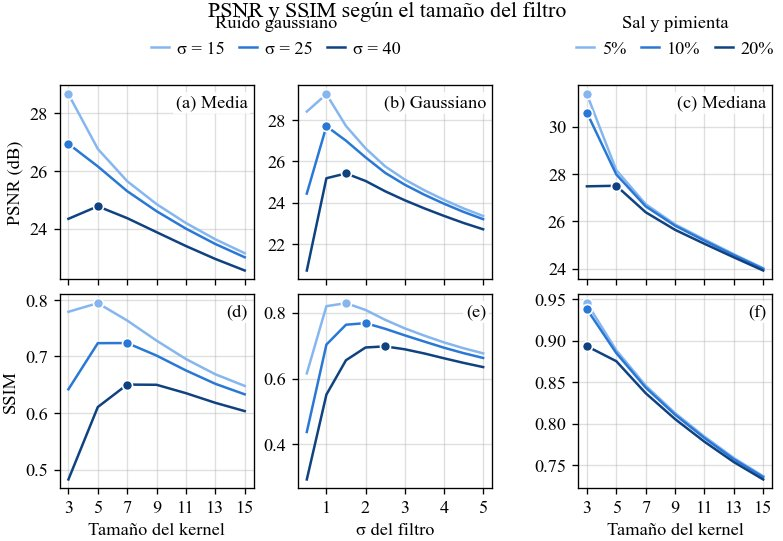

In [15]:
EJE_X = {"Media": "Tamaño del kernel", "Gaussiano": "σ del filtro", "Mediana": "Tamaño del kernel"}
# La tercera columna de la grilla queda vacía para separar el ruido gaussiano del sal y pimienta
fig, ejes = plt.subplots(2, 4, figsize=(ancho(1.0), 4.5), sharex="col", width_ratios=[1, 1, 0.12, 1])
fig.get_layout_engine().set(rect=(0, 0, 1, 0.9))   # lugar para las leyendas de arriba
for ax in ejes[:, 2]:
    ax.set_visible(False)
axs = ejes[:, [0, 1, 3]]
for ax in axs.flat:
    ax.set_box_aspect(1)   # recuadros cuadrados
for j, familia in enumerate(BARRIDO):
    tipo = BARRIDO[familia][0]
    d = barrido[barrido.familia == familia]
    for i, metrica in enumerate(("PSNR", "SSIM")):
        ax = axs[i, j]
        for color, (nivel, dn) in zip(NIVELES, d.groupby("nivel")):
            ax.plot(dn.param, dn[metrica], color=color, lw=1.5, label=nombre_ruido(tipo, nivel).replace("Gaussiano ", ""))
            mejor = dn.loc[dn[metrica].idxmax()]
            ax.plot(mejor.param, mejor[metrica], "o", color=color, ms=6, mec="white", mew=1)
        ax.grid(True)
        if i == 1:
            ax.set_xlabel(EJE_X[familia])
        if j == 0:
            ax.set_ylabel("PSNR (dB)" if metrica == "PSNR" else "SSIM")
        etiquetar(ax, LETRAS[3 * i + j], familia if i == 0 else "", derecha=True)
    axs[0, j].set_xticks(BARRIDO[familia][1] if familia != "Gaussiano" else [1, 2, 3, 4, 5])
# Una leyenda para el ruido gaussiano (columnas 1 y 2) y otra para sal y pimienta (columna 3),
# centradas sobre sus gráficos
fig.canvas.draw()
centro = lambda *aa: (min(a.get_position().x0 for a in aa) + max(a.get_position().x1 for a in aa)) / 2
for (j, titulo, x) in ((0, "Ruido gaussiano", centro(axs[0, 0], axs[0, 1])), (2, "Sal y pimienta", centro(axs[0, 2]))):
    manejadores, rotulos = axs[0, j].get_legend_handles_labels()
    rotulos = [r.replace("Sal y pimienta ", "") for r in rotulos]
    fig.legend(manejadores, rotulos, title=titulo, loc="upper center", bbox_to_anchor=(x, 1.0), ncols=3,
               frameon=False, handlelength=1.0, handletextpad=0.4, columnspacing=0.8)
fig.suptitle("PSNR y SSIM según el tamaño del filtro")
guardar(fig, "tamano_kernel")
plt.show()

El tamaño óptimo crece con el ruido. Con ruido gaussiano el SSIM pide un filtro más grande que el PSNR. Con la media el PSNR elige 3×3 o 5×5 y el SSIM 5×5 o 7×7. Con el gaussiano el PSNR elige σ = 1 o 1,5 y el SSIM entre 1,5 y 2,5. Con sal y pimienta la mediana de 3×3 es la mejor, salvo con el 20 %, donde el PSNR prefiere la de 5×5. Pasado el óptimo, las dos métricas bajan y las curvas de los tres niveles se juntan, porque el error depende cada vez más del detalle que se pierde y menos del ruido.

### Métricas y percepción

Para cada ruido se compara el orden que dan las dos métricas a los diez resultados (nueve filtros y la imagen sin filtrar). Se usa la correlación de Spearman, que compara posiciones y no valores.

In [16]:
filas = []
for (tipo, nivel), d in res.groupby(["tipo", "nivel"], sort=False):
    filas.append({"Ruido": nombre_ruido(tipo, nivel), "Spearman": d.PSNR.corr(d.SSIM, method="spearman"),
                  "Mejor según PSNR": d.loc[d.PSNR.idxmax(), "filtro"],
                  "Mejor según SSIM": d.loc[d.SSIM.idxmax(), "filtro"]})
display(pd.DataFrame(filas).set_index("Ruido").round(2))

# Pares de filtros que las métricas ordenan al revés
pares = []
for (tipo, nivel), d in res[res.familia != "Sin filtrar"].groupby(["tipo", "nivel"], sort=False):
    d = d.reset_index(drop=True)
    for a in range(len(d)):
        for b in range(len(d)):
            dp, ds = d.PSNR[a] - d.PSNR[b], d.SSIM[a] - d.SSIM[b]
            if dp > 0 and ds < 0:
                pares.append({"tipo": tipo, "nivel": nivel, "Gana en PSNR": (d.familia[a], d.param[a]),
                              "Gana en SSIM": (d.familia[b], d.param[b]), "Dif. PSNR (dB)": dp, "Dif. SSIM": -ds})
pares = pd.DataFrame(pares).sort_values("Dif. SSIM", ascending=False)
pares.head(8).round(3)

,Spearman,Mejor según PSNR,Mejor según SSIM
Ruido,,,
Gaussiano σ = 15,0.49,Gaussiano σ = 1,Gaussiano σ = 1
Gaussiano σ = 25,-0.21,Gaussiano σ = 1,Gaussiano σ = 2
Gaussiano σ = 40,0.48,Gaussiano σ = 1,Gaussiano σ = 2
Sal y pimienta 5%,0.75,Mediana 3×3,Mediana 3×3
Sal y pimienta 10%,0.92,Mediana 3×3,Mediana 3×3
Sal y pimienta 20%,0.98,Mediana 5×5,Mediana 3×3


,tipo,nivel,Gana en PSNR,Gana en SSIM,Dif. PSNR (dB),Dif. SSIM
26,Gaussiano,25,"(Mediana, 3)","(Gaussiano, 2)",0.030,0.213
40,Gaussiano,40,"(Media, 3)","(Gaussiano, 3)",0.226,0.206
27,Gaussiano,25,"(Mediana, 3)","(Gaussiano, 3)",1.350,0.176
24,Gaussiano,25,"(Mediana, 3)","(Media, 7)",0.918,0.168
23,Gaussiano,25,"(Mediana, 3)","(Media, 5)",0.060,0.168
56,Sal y pimienta,5,"(Media, 3)","(Gaussiano, 3)",0.360,0.167
46,Gaussiano,40,"(Mediana, 5)","(Gaussiano, 3)",0.700,0.159
25,Gaussiano,25,"(Mediana, 3)","(Mediana, 7)",0.417,0.157


Con sal y pimienta las dos métricas ordenan los filtros casi igual. Con ruido gaussiano no, y con σ = 25 los órdenes son casi opuestos. Con ese ruido los filtros sacan ruido a costa de perder detalle, y cada métrica pesa distinto esas dos cosas.

Caso: Gaussiano σ = 25 | Mediana 3×3 contra Gaussiano σ = 3


Mediana 3×3: PSNR 26.22 dB, SSIM 0.555


Gaussiano σ = 3: PSNR 24.87 dB, SSIM 0.731


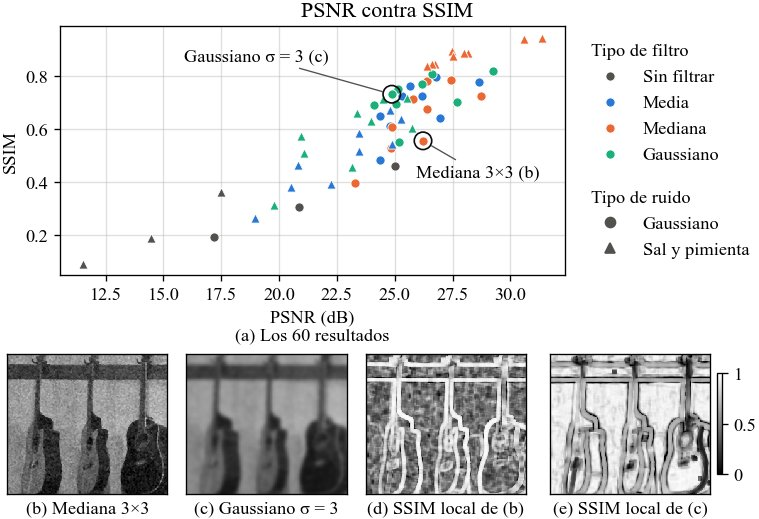

In [17]:
# Para la figura se elige el par con más diferencia de SSIM entre los que difieren en más de 0,5 dB
elegido = pares[pares["Dif. PSNR (dB)"] > 0.5].iloc[0]
CASO = (elegido.tipo, elegido.nivel)
PAR = [elegido["Gana en PSNR"], elegido["Gana en SSIM"]]
print("Caso:", nombre_ruido(*CASO), "|", nombre_filtro(*PAR[0]), "contra", nombre_filtro(*PAR[1]))
MARCAS = {"Gaussiano": "o", "Sal y pimienta": "^"}
TEXTO_PAR = [(28.6, 0.42), (19.0, 0.86)]   # dónde van los nombres del par, en zonas sin puntos

fig = plt.figure(figsize=(ancho(1.0), 4.33))
fig.get_layout_engine().set(rect=(0, 0, 0.98, 1))   # margen a la derecha para los números de la barra
sub = fig.subfigures(2, 1, height_ratios=[2.85, 1.48])
ax = sub[0].subplots()
for (familia, tipo), d in res.groupby(["familia", "tipo"], sort=False):
    ax.scatter(d.PSNR, d.SSIM, s=30, marker=MARCAS[tipo], color=COLOR.get(familia, GRIS), edgecolors="white",
               linewidths=0.5, label=familia if tipo == "Gaussiano" else None, zorder=3)
for (familia, p), xy_texto, letra in zip(PAR, TEXTO_PAR, "bc"):
    fila = res[(res.tipo == CASO[0]) & (res.nivel == CASO[1]) & (res.familia == familia) & (res.param == p)].iloc[0]
    ax.scatter(fila.PSNR, fila.SSIM, s=110, facecolors="none", edgecolors="#0b0b0b", linewidths=1, zorder=4)
    ax.annotate(f"{nombre_filtro(familia, p)} ({letra})", (fila.PSNR, fila.SSIM), xytext=xy_texto, ha="center",
                arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8, shrinkB=6))
ax.set_xlabel("PSNR (dB)\n(a) Los 60 resultados")
ax.set_ylabel("SSIM")
ax.grid(True)
# Dos leyendas: el color indica el filtro y la forma indica el ruido
manejadores, rotulos = ax.get_legend_handles_labels()
ley_filtro = ax.legend(manejadores, rotulos, title="Tipo de filtro", loc="upper left", bbox_to_anchor=(1.02, 1.0),
                       frameon=False, alignment="left")
ax.add_artist(ley_filtro)
formas = [plt.Line2D([], [], marker=m, ls="", color=GRIS) for m in MARCAS.values()]
ax.legend(formas, ["Gaussiano", "Sal y pimienta"], title="Tipo de ruido", loc="lower left", bbox_to_anchor=(1.02, 0.0),
          frameon=False, alignment="left")

axs = sub[1].subplots(1, 4)
for j, (familia, p) in enumerate(PAR):
    img = filtradas[(*CASO, familia, p)]
    ssim, mapa = structural_similarity(ref, img, data_range=255, full=True)
    print(f"{nombre_filtro(familia, p)}: PSNR {cv2.PSNR(ref, img):.2f} dB, SSIM {ssim:.3f}")
    mostrar_img(axs[j], img[RECORTE], nombre_filtro(familia, p), LETRAS[1 + j])
    mostrar_img(axs[2 + j], mapa[RECORTE], f"SSIM local de ({LETRAS[1 + j]})", LETRAS[3 + j], vmin=0, vmax=1)
barra = sub[1].colorbar(axs[3].images[0], ax=axs[3], pad=0.04, shrink=0.72, ticks=[0, 0.5, 1])
barra.ax.set_yticklabels(["0", "0.5", "1"])
fig.suptitle("PSNR contra SSIM")
guardar(fig, "metricas_percepcion")
plt.show()

En los mapas de SSIM local, la mediana pierde en la pared, donde deja ruido, y el gaussiano pierde en los bordes, que quedan borrosos. En una zona lisa cualquier resto de ruido baja mucho el SSIM, y la pared ocupa buena parte de la imagen. En el PSNR pesan más los bordes, porque ahí los errores son grandes y se elevan al cuadrado. La tabla de errores de la sección siguiente lo confirma.

### Bordes con la mediana

Se toma un perfil vertical que cruza el mostrador (zona 4) en la imagen sin ruido. Pasa por las ranuras finas entre las tablas y por dos bordes netos, arriba y abajo del mostrador. Se compara la media con la mediana del mismo tamaño. El panel (c) amplía la parte de abajo del perfil.

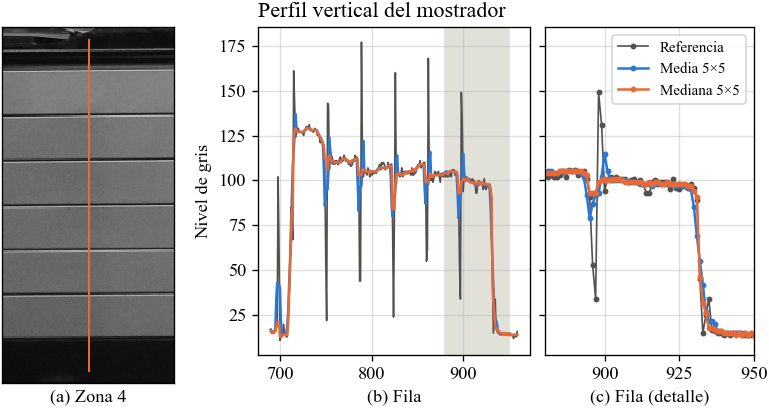

In [18]:
K_BORDE = 5
DETALLE = (880, 950)   # filas del panel ampliado
filas_y = np.arange(FILAS_PERFIL.start, FILAS_PERFIL.stop)
perfiles = {"Referencia": (ref, GRIS, 1),
            f"Media {K_BORDE}×{K_BORDE}": (cv2.blur(ref, (K_BORDE, K_BORDE)), COLOR["Media"], 1.5),
            f"Mediana {K_BORDE}×{K_BORDE}": (cv2.medianBlur(ref, K_BORDE), COLOR["Mediana"], 1.5)}

fig = plt.figure(figsize=(ancho(1.0), 3.4))
sub = fig.subfigures(1, 2, width_ratios=[0.33, 1])
ax_img = sub[0].subplots()
y, x = ZONAS[4]
mostrar_img(ax_img, ref[ZONAS[4]], "Zona 4", "a")
ax_img.plot([COL_PERFIL - x.start] * 2, [FILAS_PERFIL.start - y.start, FILAS_PERFIL.stop - y.start], color="#eb6834", lw=1.2)
axs = sub[1].subplots(1, 2, sharey=True, width_ratios=[1.3, 1])
for nombre, (img, color, lw) in perfiles.items():
    for ax in axs:
        ax.plot(filas_y, img[FILAS_PERFIL, COL_PERFIL], color=color, lw=lw, label=nombre,
                marker="o" if ax is axs[1] else None, ms=2.5)
axs[0].axvspan(*DETALLE, color="#e1e0d9", zorder=0)
axs[1].set_xlim(*DETALLE)
axs[0].set_xlabel("(b) Fila")
axs[1].set_xlabel("(c) Fila (detalle)")
axs[0].set_ylabel("Nivel de gris")
for ax in axs:
    ax.grid(True)
axs[1].legend(loc="upper right", fontsize=9)
fig.suptitle("Perfil vertical del mostrador")
guardar(fig, "perfil_borde")
plt.show()

Para medirlo en toda la imagen se separan los píxeles de borde (Canny sobre la referencia, ensanchado un píxel) de las zonas lisas (desvío local menor que 3 niveles). En cada grupo se calcula el error cuadrático medio (RMSE) contra la referencia.

In [19]:
bordes = cv2.dilate(cv2.Canny(ref, 50, 150), np.ones((3, 3), np.uint8)) > 0
media_local = cv2.blur(ref.astype(float), (7, 7))
desvio_local = np.sqrt(np.maximum(cv2.blur(ref.astype(float) ** 2, (7, 7)) - media_local ** 2, 0))
lisas = (desvio_local < 3) & ~cv2.dilate(bordes.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
print(f"Bordes: {100 * bordes.mean():.1f} % de los píxeles. Zonas lisas: {100 * lisas.mean():.1f} %")


def rmse(img, mascara):
    return np.sqrt(((img.astype(float) - ref)[mascara] ** 2).mean())


filas = []
for entrada_nombre, entrada in {"Sin ruido": ref, **{nombre_ruido(*c): RUIDOS[c] for c in [("Gaussiano", 25), ("Sal y pimienta", 10)]}}.items():
    for (familia, p), filtro in FILTROS.items():
        img = filtro(entrada)
        filas.append({"Entrada": entrada_nombre, "Filtro": nombre_filtro(familia, p),
                      "RMSE bordes": rmse(img, bordes), "RMSE lisas": rmse(img, lisas)})
errores = pd.DataFrame(filas)
errores.pivot_table(index="Filtro", columns="Entrada", values=["RMSE bordes", "RMSE lisas"], sort=False).round(1)

Bordes: 23.4 % de los píxeles. Zonas lisas: 45.8 %


RMSE bordes                                     RMSE lisas  \
Entrada           Sin ruido Gaussiano σ = 25 Sal y pimienta 10%  Sin ruido   
Filtro                                                                       
Media 3×3              16.2             18.2               23.5        1.1   
Media 5×5              22.6             23.2               25.5        1.2   
Media 7×7              25.4             25.7               27.0        1.3   
Mediana 3×3            13.2             18.1               14.9        1.1   
Mediana 5×5            19.9             22.0               20.6        1.2   
Mediana 7×7            23.6             24.7               23.9        1.3   
Gaussiano σ = 1        15.6             17.2               21.8        1.0   
Gaussiano σ = 2        22.8             23.2               24.9        1.3   
Gaussiano σ = 3        26.2             26.4               27.3        1.6   

                                                     
Entrada         Gaussiano σ = 25 Sal y pimienta 10%  
Filtro                                               
Media 3×3                    8.2               18.7  
Media 5×5                    5.8               13.5  
Media 7×7                    4.9               11.6  
Mediana 3×3                  9.8                1.8  
Mediana 5×5                  6.3                1.2  
Mediana 7×7                  4.7                1.3  
Gaussiano σ = 1              7.2               16.6  
Gaussiano σ = 2              4.9               11.6  
Gaussiano σ = 3              4.5               10.5

Sin ruido, la mediana deja el borde de abajo neto y la media lo convierte en una rampa del ancho del kernel. Pero la mediana borra las ranuras, que miden uno o dos píxeles, y la media solo las suaviza. En toda la imagen el error en los bordes de la mediana es menor que el de la media del mismo tamaño. Con ruido gaussiano la ventaja casi desaparece en 3×3, porque la mediana saca menos ruido. Con sal y pimienta la ventaja es grande.

### Media contra gaussiano

La media de 7×7 y el gaussiano de σ = 2 tienen la misma varianza espacial, porque la varianza de una caja de k píxeles es (k² − 1)/12 = 4. O sea que suavizan en la misma medida, y la diferencia está en la forma del kernel. Se compara su respuesta en frecuencia en una dimensión (los dos kernels son separables) y su efecto en dos zonas.

In [20]:
N = 1024
f = np.fft.rfftfreq(N)   # ciclos por píxel


def respuesta(kernel):
    # Respuesta en frecuencia de un kernel simétrico, centrado en 0 para que sea real
    h = np.zeros(N)
    r = len(kernel) // 2
    h[np.arange(-r, r + 1) % N] = kernel
    return np.fft.rfft(h).real


H_media = respuesta(np.ones(7) / 7)
H_gauss = respuesta(cv2.getGaussianKernel(tam_gaussiano(2), 2).ravel())
print("Varianza de la caja de 7:", (7 ** 2 - 1) / 12)
print(f"Lóbulo negativo de la media: {H_media.min():.3f} en f = {f[H_media.argmin()]:.3f} ciclos/píxel")
print(f"Gaussiano en esa frecuencia: {H_gauss[H_media.argmin()]:.3f}")
banda = f >= 0.2   # detalles de 5 píxeles o menos
print(f"Desde 0.2 ciclos/píxel deja pasar hasta {np.abs(H_media[banda]).max():.3f} la media y {np.abs(H_gauss[banda]).max():.3f} el gaussiano")

Varianza de la caja de 7: 4.0
Lóbulo negativo de la media: -0.233 en f = 0.206 ciclos/píxel
Gaussiano en esa frecuencia: 0.036
Desde 0.2 ciclos/píxel deja pasar hasta 0.233 la media y 0.043 el gaussiano


Las rayas de la pila de casetes (zona 3) tienen un período de unos 4 píxeles. Se mide cuánto queda de esa frecuencia después de cada filtro, y con qué fase, sobre el perfil vertical de la pila promediado entre columnas.

In [21]:
def componente(img, frec):
    # Amplitud compleja de las rayas en la frecuencia `frec`, en el interior de la pila
    p = img[328:352, 300:340].astype(float).mean(axis=1)
    y = np.arange(len(p))
    return np.sum((p - p.mean()) * np.exp(-2j * np.pi * frec * y))


frecs = np.linspace(0.15, 0.35, 201)
f_rayas = frecs[np.argmax([abs(componente(ref, fr)) for fr in frecs])]
print(f"Frecuencia de las rayas: {f_rayas:.3f} ciclos/píxel (período {1 / f_rayas:.1f} píxeles)")
for nombre, img, H in (("Media 7×7", cv2.blur(ref, (7, 7)), H_media), ("Gaussiano σ = 2", gaussiano(ref, 2), H_gauss)):
    g = componente(img, f_rayas) / componente(ref, f_rayas)
    teorica = np.interp(f_rayas, f, H)
    print(f"{nombre}: queda {abs(g):.3f} de la amplitud, desfase {np.degrees(np.angle(g)):.0f}°, ganancia teórica {teorica:.3f}")

Frecuencia de las rayas: 0.255 ciclos/píxel (período 3.9 píxeles)
Media 7×7: queda 0.119 de la amplitud, desfase -180°, ganancia teórica -0.124
Gaussiano σ = 2: queda 0.007 de la amplitud, desfase 1°, ganancia teórica 0.006


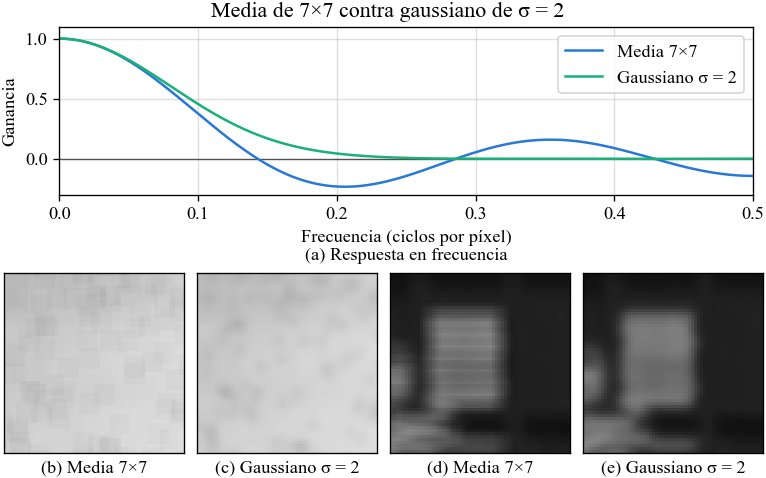

In [22]:
pared_sp = RUIDOS[("Sal y pimienta", 5)]
paneles = [(cv2.blur(pared_sp, (7, 7))[ZONAS[2]], "Media 7×7"), (gaussiano(pared_sp, 2)[ZONAS[2]], "Gaussiano σ = 2"),
           (cv2.blur(ref, (7, 7))[ZONAS[3]], "Media 7×7"), (gaussiano(ref, 2)[ZONAS[3]], "Gaussiano σ = 2")]

fig = plt.figure(figsize=(ancho(1.0), 3.95))
fig.get_layout_engine().set(rect=(0, 0, 0.99, 1))   # más margen a la derecha
sub = fig.subfigures(2, 1, height_ratios=[2.15, 1.8])
ax = sub[0].subplots()
ax.axhline(0, color=GRIS, lw=0.8)
ax.plot(f, H_media, color=COLOR["Media"], lw=1.5, label="Media 7×7")
ax.plot(f, H_gauss, color=COLOR["Gaussiano"], lw=1.5, label="Gaussiano σ = 2")
ax.set_xlim(0, 0.5)
ax.set_ylim(-0.3, 1.1)
ax.set_xlabel("Frecuencia (ciclos por píxel)\n(a) Respuesta en frecuencia")
ax.set_ylabel("Ganancia")
ax.grid(True)
ax.legend(loc="upper right")
axs = sub[1].subplots(1, 4)
for i, (ax, (img, texto)) in enumerate(zip(axs, paneles)):
    mostrar_img(ax, img, texto, LETRAS[1 + i])
fig.suptitle("Media de 7×7 contra gaussiano de σ = 2")
guardar(fig, "media_gaussiano")
plt.show()

La media de 7×7 tiene ganancia negativa entre 1/7 y 2/7 ciclos por píxel, y otra vez desde 3/7. En esas frecuencias invierte el contraste y deja detalle falso. El gaussiano baja de forma continua y desde 0,2 ciclos por píxel casi no deja pasar nada. En la pared con sal y pimienta (zona 2), cada impulso se vuelve un cuadrado de 7×7 con la media y una mancha redonda con el gaussiano. En los casetes (zona 3), la media deja rayas con la fase invertida y el gaussiano las borra.

### Bitácora

| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Barrido fino | Media y gaussiano con ruido gaussiano, mediana con sal y pimienta | Los filtros lineales son los pensados para ruido gaussiano y la mediana para ruido impulsivo | Las nueve combinaciones de filtro y ruido | Demasiadas curvas para un solo gráfico | — |
| Orden de las métricas | Correlación de Spearman entre PSNR y SSIM para cada ruido | Interesa si eligen el mismo filtro, no si los valores son proporcionales | Correlación de Pearson | Las dos métricas tienen escalas distintas y no lineales | — |
| Caso para comparar métricas | El par que las métricas ordenan al revés con más diferencia de SSIM, entre los que difieren en más de 0,5 dB | Las dos métricas tienen que mostrar una diferencia clara | El par con más diferencia de SSIM sin otra condición | La diferencia de PSNR podía ser de centésimas, o sea un empate | Métrica |
| Perfil de bordes | Columna 400 del mostrador, media y mediana de 5×5 | Cruza dos bordes netos y ranuras finas en el mismo perfil | Un perfil por las guitarras | Mezcla muchos objetos y cuesta leerlo | Visual |
| Bordes y zonas lisas | Canny ensanchado y desvío local menor que 3 | Separa los dos casos donde los filtros se comportan distinto | — | — | — |
| Comparación media y gaussiano | Media 7×7 contra gaussiano σ = 2 | Tienen la misma varianza espacial, así que suavizan lo mismo | Media 7×7 contra gaussiano σ = 1 | El gaussiano suavizaría menos y la comparación no sería pareja | — |